# Pump System Effectiveness (SE): Forecasting the next 30 days

**Goal:** predict the pump's System Effectiveness for every day from **16 Nov 2026 to 15 Dec 2026**, using daily data from 1 Jan to 15 Nov 2026.

**What the data tells us (we will prove each point below):**
1. After maintenance SE jumps above 100% and then **declines in a straight line** (about 0.13 percentage points per day).
2. That decline rate is **the same in every period**, even though the starting level differs.
3. There are also **outages** (SE drops to 0% or about half) and one-off **level shifts** (SE steps down by a few points). These are not part of the slow wear-out trend.

**Approach:** a *piecewise-linear degradation model*: one shared decay slope plus a separate starting level for each period. We backtest it against simpler alternatives before trusting it.

**Steps**
1. Load and clean the data
2. Explore it visually
3. Separate "normal degradation" from outages and level shifts
4. Fit the degradation model
5. Backtest (how wrong would it have been in the past?)
6. Forecast the next 30 days with an uncertainty band
7. Save results and read the caveats

## Step 1: Load and clean the data
The dates are **day/month/year** and SE is text like `85%`, so we must parse both explicitly. Without `dayfirst`, `02/01/2026` would be read as 1 February.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3})

CSV_PATH = "Pump_SE_CSV.csv"   # the CSV is in the same folder as this notebook

df = pd.read_csv(CSV_PATH, encoding="utf-8-sig")   # utf-8-sig removes a hidden BOM character
df.columns = ["Date", "SE"]
df["Date"] = pd.to_datetime(df["Date"], format="%d/%m/%Y")
df["SE"] = df["SE"].str.rstrip("%").astype(float)
df = df.set_index("Date").sort_index()
s = df["SE"]

# Sanity checks: no gaps, no duplicates, no missing values
print("Rows:", len(s), "| From", s.index.min().date(), "to", s.index.max().date())
print("Missing values:", s.isna().sum(), "| Duplicate dates:", s.index.duplicated().sum())
print("All gaps are exactly 1 day:", (s.index.to_series().diff().dropna() == pd.Timedelta(days=1)).all())
s.describe()

Rows: 319 | From 2026-01-01 to 2026-11-15
Missing values: 0 | Duplicate dates: 0
All gaps are exactly 1 day: True


count    319.000000
mean      82.423197
std       38.425779
min        0.000000
25%       83.000000
50%       93.000000
75%      108.000000
max      128.000000
Name: SE, dtype: float64

## Step 2: Look at the data
We plot first. The shape of the data decides which model makes sense.

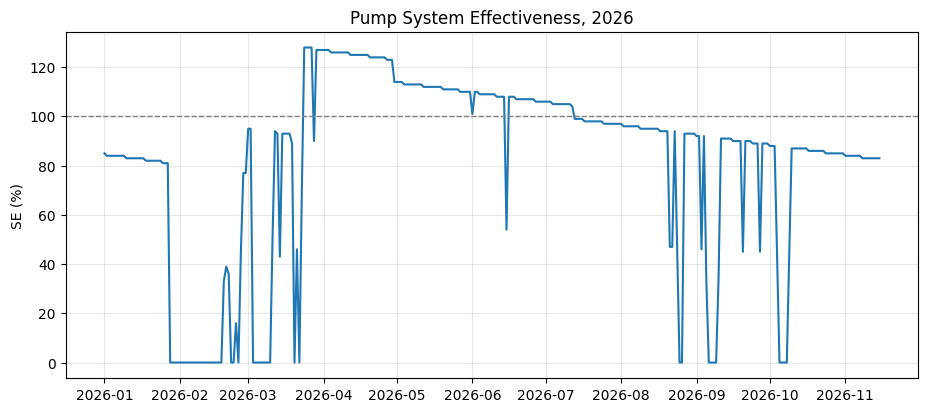

In [2]:
fig, ax = plt.subplots()
ax.plot(s.index, s.values, lw=1.5)
ax.axhline(100, color="grey", ls="--", lw=1)
ax.set_title("Pump System Effectiveness, 2026")
ax.set_ylabel("SE (%)")
plt.show()

What we see:
- **Jan 1-27:** slow decline from 85% to 81%, then the pump fails (0%).
- **Feb-Mar 23:** mostly 0% (down, being repaired, restarting).
- **Mar 24:** big jump to 128% after thorough maintenance, then a steady decline.
- **Later:** two small downward steps (30 Apr, 13 Jul) and several outage days (dips to 0% or about half).

We will model **only the slow decline after the last maintenance (24 Mar onward)**. The Jan-Mar data is a different regime (failure and repair) and would mislead the model.

## Step 3: Separate normal degradation from outages and level shifts
**Outages** are single days or short runs far below the local trend. We flag any day more than 6 points below the 15-day rolling median.

In [3]:
MAINT_DATE = pd.Timestamp("2026-03-24")        # last thorough maintenance (SE jumps to 128%)
post = s[MAINT_DATE:]

post.head()

Date
2026-03-24    128.0
2026-03-25    128.0
2026-03-26    128.0
2026-03-27    128.0
2026-03-28     90.0
Name: SE, dtype: float64

In [4]:
rolling_med = post.rolling(15, center=True, min_periods=5).median()
rolling_med

Date
2026-03-24    127.5
2026-03-25    127.0
2026-03-26    127.0
2026-03-27    127.0
2026-03-28    127.0
              ...  
2026-11-11     83.0
2026-11-12     83.0
2026-11-13     83.0
2026-11-14     83.0
2026-11-15     83.0
Name: SE, Length: 237, dtype: float64

In [5]:

is_outage = post < (rolling_med - 6)

clean = post[~is_outage].copy()
print(f"Days after maintenance: {len(post)} | flagged as outage/partial-outage: {is_outage.sum()} | kept: {len(clean)}")

clean.head()

Days after maintenance: 237 | flagged as outage/partial-outage: 23 | kept: 214


Date
2026-03-24    128.0
2026-03-25    128.0
2026-03-26    128.0
2026-03-27    128.0
2026-03-29    127.0
Name: SE, dtype: float64

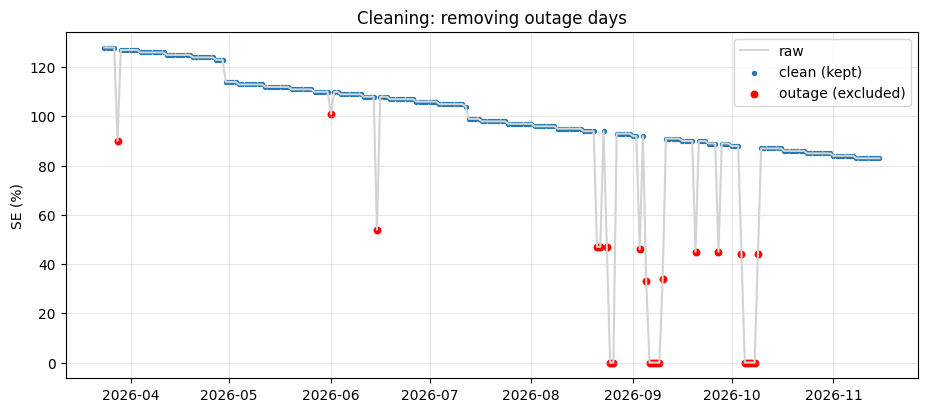

In [6]:
fig, ax = plt.subplots()
ax.plot(post.index, post.values, color="lightgrey", label="raw")
ax.scatter(clean.index, clean.values, s=8, label="clean (kept)")
ax.scatter(post.index[is_outage], post[is_outage], s=22, color="red", label="outage (excluded)")
ax.set_title("Cleaning: removing outage days"); ax.set_ylabel("SE (%)"); ax.legend()
plt.show()

**Level shifts:** the remaining series still has sudden *downward steps* (not outages, because SE stays at the new level). We detect them as day-to-day drops of 3+ points. Each step starts a new "segment".

In [7]:
diff = clean.diff()
shift_dates = diff[diff <= -3].index
print("Detected level shifts:")
print(diff[shift_dates].to_string())


Detected level shifts:
Date
2026-04-30   -9.0
2026-07-13   -5.0


In [8]:
# Segment id increases by 1 at the maintenance date and at each level shift
seg_id = pd.Series(0, index=clean.index)
for d in shift_dates:
    seg_id[seg_id.index >= d] += 1
clean = clean.to_frame("SE")
clean["segment"] = seg_id
clean["t"] = (clean.index - MAINT_DATE).days      # days since maintenance

# Is the decay rate really the same in each segment?
rows = []
for k, g in clean.groupby("segment"):
    slope, intercept = np.polyfit(g["t"], g["SE"], 1)
    rows.append({"segment": k, "start": g.index.min().date(), "end": g.index.max().date(),
                 "days": len(g), "slope_pts_per_day": round(slope, 4)})
pd.DataFrame(rows)

,segment,start,end,days,slope_pts_per_day
0,0,2026-03-24,2026-04-29,36,-0.1358
1,1,2026-04-30,2026-07-12,72,-0.1313
2,2,2026-07-13,2026-11-15,106,-0.1316


**Key finding:** the slope is about **-0.131 points/day in every segment**. The pump wears out at a constant rate; what changes between segments is only the starting level. So we can safely **pool** the data to estimate one precise slope, instead of trusting a short recent window.

## Step 4: Fit the model

$$SE_t = \text{level}_{\text{segment}(t)} + \text{slope}\times t + \text{noise}$$

Ordinary least squares with one intercept per segment (dummy variables) and one shared slope. We use plain NumPy so there is nothing extra to install.

Shared decay slope: -0.1316 points/day  (~0.92 points/week)
Current segment (2) intercept: 113.63
In-sample RMSE: 0.290 points  (the data is rounded to whole %, so ~0.3 is the floor)


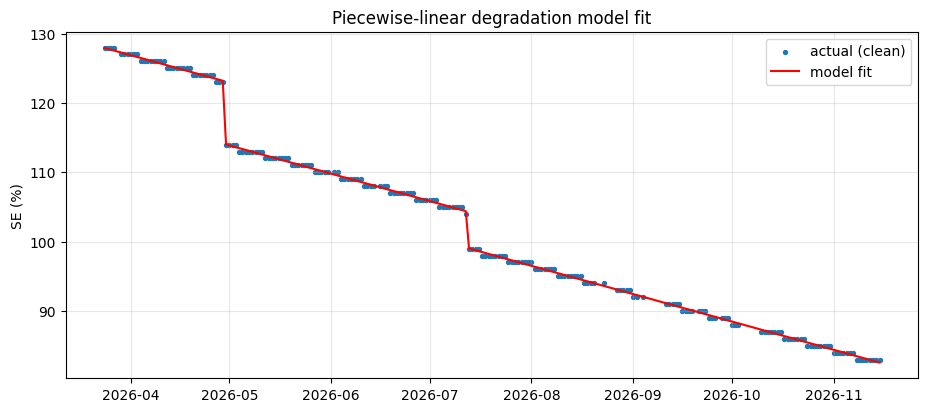

In [9]:
def fit_shared_slope(d):
    """Least squares with a separate intercept per segment and one shared slope."""
    segs = sorted(d["segment"].unique())
    X = np.column_stack([(d["segment"] == k).astype(float) for k in segs] + [d["t"].values])
    beta, *_ = np.linalg.lstsq(X, d["SE"].values, rcond=None)
    return dict(zip(segs, beta[:-1])), beta[-1]

levels, slope = fit_shared_slope(clean)
last_seg = clean["segment"].max()
print(f"Shared decay slope: {slope:.4f} points/day  (~{-slope*7:.2f} points/week)")
print(f"Current segment ({last_seg}) intercept: {levels[last_seg]:.2f}")

fitted = clean["segment"].map(levels) + slope * clean["t"]
resid = clean["SE"] - fitted
print(f"In-sample RMSE: {np.sqrt((resid**2).mean()):.3f} points  (the data is rounded to whole %, so ~0.3 is the floor)")

fig, ax = plt.subplots()
ax.scatter(clean.index, clean["SE"], s=8, label="actual (clean)")
ax.plot(clean.index, fitted, color="red", lw=1.5, label="model fit")
ax.set_title("Piecewise-linear degradation model fit"); ax.set_ylabel("SE (%)"); ax.legend()
plt.show()

## Step 5: Backtest, i.e. check whether the model deserves trust
A good fit on past data proves little. The real test: **pretend it is an earlier date, forecast the next 30 days, and compare with what actually happened.** We repeat this from many start dates ("rolling origin") and compare against simpler alternatives:

| Model | Idea |
|---|---|
| **Persistence** | tomorrow = today's last value |
| **Last-30-days line** | straight line through the most recent 30 clean days |
| **Shared-slope (ours)** | pooled slope from all past segments, level taken from the latest segment |

Errors are measured on clean actual days (outage days can't be predicted by a wear-out model; see Step 7).

In [10]:
H = 30
def forecast_shared(train, horizon=H):
    lv, sl = fit_shared_slope(train)
    last = train["segment"].max()
    t0 = train["t"].iloc[-1]
    ts = np.arange(t0 + 1, t0 + horizon + 1)
    return lv[last] + sl * ts

def forecast_persistence(train, horizon=H):
    return np.repeat(train["SE"].iloc[-1], horizon)

def forecast_last30(train, horizon=H):
    w = train.iloc[-30:]
    sl, ic = np.polyfit(w["t"], w["SE"], 1)
    ts = np.arange(train["t"].iloc[-1] + 1, train["t"].iloc[-1] + horizon + 1)
    return ic + sl * ts

models = {"Persistence": forecast_persistence, "Last-30-days line": forecast_last30, "Shared-slope (ours)": forecast_shared}

# Daily calendar of actual values (NaN where the day was an outage/excluded)
cal = clean.reindex(pd.date_range(clean.index.min(), clean.index.max()))
errs = {m: [] for m in models}
origins = pd.date_range("2026-05-15", clean.index.max() - pd.Timedelta(days=H), freq="7D")

for o in origins:
    train = clean[:o]
    train = train[train.index <= o]
    if len(train) < 30: 
        continue
    future_idx = pd.date_range(o + pd.Timedelta(days=1), periods=H)
    actual = cal["SE"].reindex(future_idx)
    for m, f in models.items():
        pred = pd.Series(f(train), index=future_idx)
        errs[m].append((pred - actual).dropna())

summary = pd.DataFrame({
    m: {"MAE (pts)": pd.concat(e).abs().mean(),
        "RMSE (pts)": np.sqrt((pd.concat(e) ** 2).mean()),
        "Worst error (pts)": pd.concat(e).abs().max()}
    for m, e in errs.items()
}).T.round(2)
print(f"{len(origins)} forecast origins, 30-day horizon each")
summary

23 forecast origins, 30-day horizon each


,MAE (pts),RMSE (pts),Worst error (pts)
Persistence,2.70,3.56,10.00
Last-30-days line,2.19,3.79,16.06
Shared-slope (ours),0.87,1.83,5.77


Reading the table: lower is better. The persistence forecast ignores the decline, so it gets worse the further ahead it looks. The shared-slope model should win or tie. If a level shift occurred inside a test window, all models are hurt equally, because **no trend model can see a sudden step coming**. That is why the "worst error" column matters and why we build an uncertainty band from these errors next.

## Step 6: Forecast 16 Nov to 15 Dec 2026
We refit on **all** clean data, project 30 days, and add an uncertainty band taken from the backtest errors (the 10th and 90th percentile of how wrong the model has actually been at each horizon).

In [11]:
# Final model on all data
levels, slope = fit_shared_slope(clean)
last_seg = clean["segment"].max()
t_last = clean["t"].iloc[-1]

future_dates = pd.date_range("2026-11-16", periods=30)
t_future = (future_dates - MAINT_DATE).days
point = levels[last_seg] + slope * t_future

# Empirical error band by horizon (from the backtest of OUR model)
err_by_h = {h: [] for h in range(1, H + 1)}
for o in origins:
    train = clean[:o]
    if len(train) < 30: continue
    idx = pd.date_range(o + pd.Timedelta(days=1), periods=H)
    pred = pd.Series(forecast_shared(train), index=idx)
    e = (cal["SE"].reindex(idx) - pred)
    for h, v in enumerate(e.values, start=1):
        if not np.isnan(v): err_by_h[h].append(v)

lo_q = np.array([np.percentile(err_by_h[h], 10) if err_by_h[h] else 0 for h in range(1, H + 1)])
hi_q = np.array([np.percentile(err_by_h[h], 90) if err_by_h[h] else 0 for h in range(1, H + 1)])

forecast = pd.DataFrame({
    "Predicted SE (%)": point.round(1),
    "Lower (10th pct)": (point + np.minimum(lo_q, 0)).round(1),
    "Upper (90th pct)": (point + np.maximum(hi_q, 0)).round(1),
}, index=future_dates)
forecast.index.name = "Date"
forecast

,Predicted SE (%),Lower (10th pct),Upper (90th pct)
Date,,,
2026-11-16,82.4,82.0,82.8
2026-11-17,82.3,81.9,82.6
2026-11-18,82.2,81.6,82.5
2026-11-19,82.0,81.6,82.5
2026-11-20,81.9,81.4,82.4
2026-11-21,81.8,81.3,82.1
2026-11-22,81.6,81.3,82.0
2026-11-23,81.5,81.0,81.9
2026-11-24,81.4,80.8,81.7


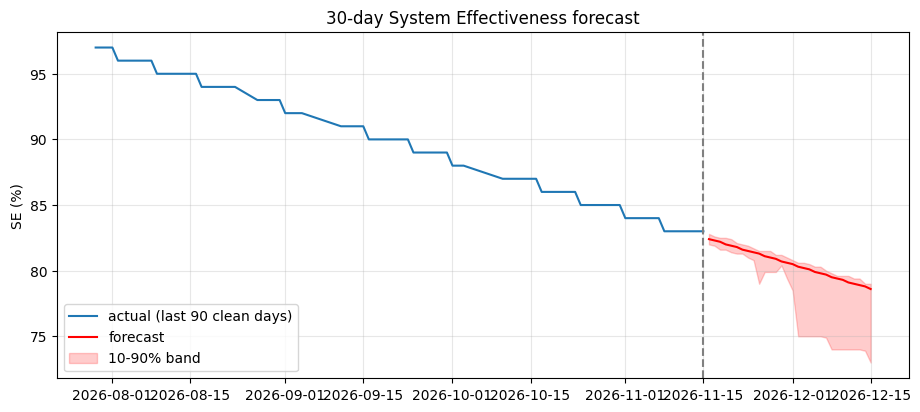

15 Nov (last actual): 83%
16 Nov forecast:      82.4%
15 Dec forecast:      78.6%


In [12]:
fig, ax = plt.subplots()
hist = clean["SE"][-90:]
ax.plot(hist.index, hist.values, label="actual (last 90 clean days)")
ax.plot(forecast.index, forecast["Predicted SE (%)"], color="red", label="forecast")
ax.fill_between(forecast.index, forecast["Lower (10th pct)"], forecast["Upper (90th pct)"], color="red", alpha=0.2, label="10-90% band")
ax.axvline(pd.Timestamp("2026-11-15"), color="grey", ls="--")
ax.set_title("30-day System Effectiveness forecast"); ax.set_ylabel("SE (%)"); ax.legend()
plt.show()

print(f"15 Nov (last actual): {s.iloc[-1]:.0f}%")
print(f"16 Nov forecast:      {forecast.iloc[0, 0]:.1f}%")
print(f"15 Dec forecast:      {forecast.iloc[-1, 0]:.1f}%")

## Step 7: Save results and understand the limits

In [13]:
forecast.to_csv("Pump_SE_forecast_16Nov-15Dec2026.csv")
print("Saved Pump_SE_forecast_16Nov-15Dec2026.csv")

# How often did outages happen? Useful context, not part of the trend forecast.
n_post = len(post)
print(f"\nSince maintenance: {is_outage.sum()} of {n_post} days ({is_outage.mean():.0%}) were outage/partial-outage days.")
print("Outage days by month:"); print(is_outage.groupby(post.index.month).sum().to_string())
print("\nLevel shifts so far:", [d.date().isoformat() for d in shift_dates])

Saved Pump_SE_forecast_16Nov-15Dec2026.csv

Since maintenance: 23 of 237 days (10%) were outage/partial-outage days.
Outage days by month:
Date
3     1
4     0
5     0
6     2
7     0
8     5
9     9
10    6
11    0

Level shifts so far: ['2026-04-30', '2026-07-13']


### How to read the forecast, and what it cannot do
- **It predicts wear-out, not events.** The point forecast assumes the pump keeps running and decays at its usual rate. It cannot predict outages (0% days), sudden level shifts, or maintenance.
- **If maintenance is done in the window**, SE will jump above 100% and this forecast no longer applies. Restart from Step 3 with the new maintenance date as `MAINT_DATE`.
- **Outage risk is separate.** Step 7 shows how frequent outages have been. The last outage run was early October, so the near-term risk is not zero but has been lower recently. A stricter planning number is the *Lower* column.
- **Only one maintenance event** (24 Mar) is in the data. To predict *how high* SE jumps after the next maintenance, you need more maintenance history; a single example can't support that.
- **Retrain regularly.** Append new rows to the CSV and re-run the notebook; the model refits itself.

### Ideas to extend later
- Add a maintenance log and operating-hours/load columns; these usually explain level shifts and outages.
- Model outage probability separately (e.g. a simple classifier) and combine with this trend for an *expected* SE.
- With a year or more of data, test exponential or Weibull-style wear curves against the straight line.